# Step 1 — Add the notebook introduction

# FounderVerse — SaaS Dataset Exploration

## Objective
Explore and validate the SaaS Subscriptions & Customer Churn dataset
before using it for business analysis, simulation, and reinforcement learning.

## Dataset
- Industry: B2B SaaS
- Source type: Synthetic
- Coverage: January 2023 – December 2025
- Tables: Accounts, Subscriptions, Plans, Invoices, Payments

## Workflow
1. Load the raw CSV files
2. Inspect schemas, data types, and missing values
3. Check duplicate records and primary keys
4. Validate relationships between tables
5. Explore subscription, revenue, billing, and payment patterns
6. Document data quality issues and next steps

**Important:** Raw source data will not be modified.

# Step 2 — Import libraries and locate the dataset

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

# Locate the project root
cwd = Path.cwd()

if (cwd / "data").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "data").exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError(
        "Could not find the project data folder. "
        "Check which folder Jupyter opened."
    )

DATA_DIR = PROJECT_ROOT / "data"

print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)

Project root: C:\Users\HP\Downloads\FounderVerse_AI Agents
Data directory: C:\Users\HP\Downloads\FounderVerse_AI Agents\data


# Step 3 — Find and load the five tables

In [2]:
required_files = [
    "accounts.csv",
    "subscriptions.csv",
    "plans.csv",
    "invoices.csv",
    "payments.csv",
]

# Search recursively, including subfolders
available_files = {}

for file_path in DATA_DIR.rglob("*.csv"):
    available_files[file_path.name.lower()] = file_path

missing_files = [
    name for name in required_files
    if name.lower() not in available_files
]

if missing_files:
    print("Missing files:", missing_files)
    print("\nCSV files found:")
    for path in DATA_DIR.rglob("*.csv"):
        print(path)
    raise FileNotFoundError(
        "Some required CSV files were not found. "
        "Check the paths printed above."
    )

# Load each CSV into a separate DataFrame
accounts = pd.read_csv(available_files["accounts.csv"])
subscriptions = pd.read_csv(available_files["subscriptions.csv"])
plans = pd.read_csv(available_files["plans.csv"])
invoices = pd.read_csv(available_files["invoices.csv"])
payments = pd.read_csv(available_files["payments.csv"])

tables = {
    "accounts": accounts,
    "subscriptions": subscriptions,
    "plans": plans,
    "invoices": invoices,
    "payments": payments,
}

print("All five tables loaded successfully!")

All five tables loaded successfully!


# Step 4 — Inspect the tables

In [3]:
overview = []

for table_name, df in tables.items():
    overview.append({
        "table": table_name,
        "rows": len(df),
        "columns": len(df.columns),
        "duplicate_rows": int(df.duplicated().sum()),
        "total_missing_cells": int(df.isna().sum().sum()),
    })

overview_df = pd.DataFrame(overview)
display(overview_df)

,table,rows,columns,duplicate_rows,total_missing_cells
0,accounts,5000,5,0,1247
1,subscriptions,5000,8,0,4035
2,plans,4,4,0,0
3,invoices,85448,6,0,0
4,payments,87287,5,0,0


In [4]:
for table_name, df in tables.items():
    print(f"\n{'=' * 60}")
    print(f"TABLE: {table_name.upper()}")
    print(f"{'=' * 60}")

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nData types:")
    print(df.dtypes)

    print("\nFirst 5 rows:")
    display(df.head())


TABLE: ACCOUNTS

Columns:
['account_id', 'created_at', 'region', 'segment', 'acquisition_channel']

Data types:
account_id             str
created_at             str
region                 str
segment                str
acquisition_channel    str
dtype: object

First 5 rows:


,account_id,created_at,region,segment,acquisition_channel
0,A000001,2024-05-24,LATAM,SMB,organic
1,A000002,2025-03-18,APAC,SMB,organic
2,A000003,2024-07-03,APAC,SMB,paid_search
3,A000004,2024-01-12,EMEA,SMB,referral
4,A000005,2025-09-06,LATAM,mid_market,outbound



TABLE: SUBSCRIPTIONS

Columns:
['subscription_id', 'account_id', 'plan_id', 'started_at', 'ended_at', 'status', 'seats', 'mrr']

Data types:
subscription_id        str
account_id             str
plan_id                str
started_at             str
ended_at               str
status                 str
seats                int64
mrr                float64
dtype: object

First 5 rows:


,subscription_id,account_id,plan_id,started_at,ended_at,status,seats,mrr
0,S000001,A000001,PLN_GROWTH,2024-06-11,NaN,active,13,199.00
1,S000002,A000002,PLN_STARTER,2025-04-07,NaN,active,3,49.00
2,S000003,A000003,PLN_GROWTH,2024-07-24,NaN,active,7,199.00
3,S000004,A000004,PLN_STARTER,2024-01-14,NaN,active,4,49.00
4,S000005,A000005,PLN_SCALE,2025-09-30,NaN,active,79,799.00



TABLE: PLANS

Columns:
['plan_id', 'plan_name', 'monthly_price', 'included_seats']

Data types:
plan_id               str
plan_name             str
monthly_price     float64
included_seats      int64
dtype: object

First 5 rows:


,plan_id,plan_name,monthly_price,included_seats
0,PLN_STARTER,Starter,49.00,5
1,PLN_GROWTH,Growth,199.00,20
2,PLN_SCALE,Scale,799.00,100
3,PLN_ENTERPRISE,Enterprise,"2,499.00",500



TABLE: INVOICES

Columns:
['invoice_id', 'subscription_id', 'invoice_date', 'due_date', 'amount_due', 'invoice_status']

Data types:
invoice_id             str
subscription_id        str
invoice_date           str
due_date               str
amount_due         float64
invoice_status         str
dtype: object

First 5 rows:


,invoice_id,subscription_id,invoice_date,due_date,amount_due,invoice_status
0,INV0000001,S000001,2024-06-11,2024-06-26,199.00,paid
1,INV0000002,S000001,2024-07-11,2024-07-26,199.00,paid
2,INV0000003,S000001,2024-08-11,2024-08-26,199.00,paid
3,INV0000004,S000001,2024-09-11,2024-09-26,199.00,paid
4,INV0000005,S000001,2024-10-11,2024-10-26,199.00,paid



TABLE: PAYMENTS

Columns:
['payment_id', 'invoice_id', 'attempted_at', 'payment_status', 'amount']

Data types:
payment_id            str
invoice_id            str
attempted_at          str
payment_status        str
amount            float64
dtype: object

First 5 rows:


,payment_id,invoice_id,attempted_at,payment_status,amount
0,SPAY0000001,INV0000001,2024-06-14,succeeded,199.00
1,SPAY0000002,INV0000002,2024-07-14,succeeded,199.00
2,SPAY0000003,INV0000003,2024-08-12,failed,199.00
3,SPAY0000004,INV0000003,2024-08-14,succeeded,199.00
4,SPAY0000005,INV0000004,2024-09-14,succeeded,199.00


# Step 5 — Check missing values

In [5]:
missing_summary = []

for table_name, df in tables.items():
    for column in df.columns:
        missing_count = int(df[column].isna().sum())

        missing_summary.append({
            "table": table_name,
            "column": column,
            "missing_count": missing_count,
            "missing_percent": (
                missing_count / len(df) * 100
                if len(df) > 0 else 0
            ),
        })

missing_df = pd.DataFrame(missing_summary)

display(
    missing_df[missing_df["missing_count"] > 0]
    .sort_values("missing_percent", ascending=False)
    .reset_index(drop=True)
)

,table,column,missing_count,missing_percent
0,subscriptions,ended_at,4035,80.70
1,accounts,region,1247,24.94


# Step 6 — Validate primary keys

In [6]:
primary_keys = {
    "accounts": "account_id",
    "subscriptions": "subscription_id",
    "plans": "plan_id",
    "invoices": "invoice_id",
    "payments": "payment_id",
}

key_results = []

for table_name, key in primary_keys.items():
    df = tables[table_name]

    key_results.append({
        "table": table_name,
        "key": key,
        "missing_keys": int(df[key].isna().sum()),
        "unique_keys": int(df[key].nunique()),
        "total_rows": len(df),
        "duplicate_keys": int(df[key].duplicated().sum()),
    })

key_check_df = pd.DataFrame(key_results)
display(key_check_df)

,table,key,missing_keys,unique_keys,total_rows,duplicate_keys
0,accounts,account_id,0,5000,5000,0
1,subscriptions,subscription_id,0,5000,5000,0
2,plans,plan_id,0,4,4,0
3,invoices,invoice_id,0,85448,85448,0
4,payments,payment_id,0,87287,87287,0


## 2. Referential Integrity

We validate the foreign-key relationships between the five source tables.

The checks identify:
- Subscriptions linked to nonexistent accounts or plans
- Invoices linked to nonexistent subscriptions
- Payments linked to nonexistent invoices

We also check whether the relationships match the expected
many-to-one structure.

In [7]:
# Foreign-key relationships:
# (child table, child column, parent table, parent column)

relationships = [
    ("subscriptions", "account_id", "accounts", "account_id"),
    ("subscriptions", "plan_id", "plans", "plan_id"),
    ("invoices", "subscription_id", "subscriptions", "subscription_id"),
    ("payments", "invoice_id", "invoices", "invoice_id"),
]

relationship_results = []

for child_table, child_col, parent_table, parent_col in relationships:
    child_df = tables[child_table]
    parent_df = tables[parent_table]

    parent_keys = set(parent_df[parent_col].dropna())
    child_values = child_df[child_col]

    missing_fk = int(child_values.isna().sum())
    orphan_mask = (
        child_values.notna()
        & ~child_values.isin(parent_keys)
    )

    relationship_results.append({
        "relationship": f"{child_table}.{child_col} -> "
                        f"{parent_table}.{parent_col}",
        "child_rows": len(child_df),
        "missing_foreign_keys": missing_fk,
        "orphan_records": int(orphan_mask.sum()),
        "valid_references": int(
            child_values.notna().sum() - orphan_mask.sum()
        ),
    })

relationship_df = pd.DataFrame(relationship_results)
display(relationship_df)

,relationship,child_rows,missing_foreign_keys,orphan_records,valid_references
0,subscriptions.account_id -> accounts.account_id,5000,0,0,5000
1,subscriptions.plan_id -> plans.plan_id,5000,0,0,5000
2,invoices.subscription_id -> subscriptions.subs...,85448,0,0,85448
3,payments.invoice_id -> invoices.invoice_id,87287,0,0,87287


# Check subscription status against ended_at

In [8]:
# Inspect the values present in the subscription status column
print("Subscription status distribution:")
display(
    subscriptions["status"]
    .value_counts(dropna=False)
    .rename_axis("status")
    .reset_index(name="count")
)

# Compare status with the presence of an end date
subscriptions["has_ended_at"] = (
    subscriptions["ended_at"].notna()
)

status_end_check = pd.crosstab(
    subscriptions["status"],
    subscriptions["has_ended_at"],
    margins=True
)

display(status_end_check)

Subscription status distribution:


,status,count
0,active,4035
1,cancelled,965


has_ended_at,False,True,All
status,,,
active,4035,0,4035
cancelled,0,965,965
All,4035,965,5000


# Check date validity

In [9]:
date_columns = {
    "accounts": ["created_at"],
    "subscriptions": ["started_at", "ended_at"],
    "invoices": ["invoice_date", "due_date"],
    "payments": ["attempted_at"],
}

date_results = []

for table_name, columns in date_columns.items():
    df = tables[table_name]

    for column in columns:
        parsed_dates = pd.to_datetime(
            df[column],
            errors="coerce"
        )

        invalid_mask = (
            df[column].notna()
            & parsed_dates.isna()
        )

        date_results.append({
            "table": table_name,
            "column": column,
            "non_missing_dates": int(df[column].notna().sum()),
            "invalid_dates": int(invalid_mask.sum()),
            "earliest_date": parsed_dates.min(),
            "latest_date": parsed_dates.max(),
        })

date_check_df = pd.DataFrame(date_results)
display(date_check_df)

,table,column,non_missing_dates,invalid_dates,earliest_date,latest_date
0,accounts,created_at,5000,0,2023-01-01,2025-09-30
1,subscriptions,started_at,5000,0,2023-01-04,2025-10-29
2,subscriptions,ended_at,965,0,2023-04-26,2025-12-30
3,invoices,invoice_date,85448,0,2023-01-04,2025-12-28
4,invoices,due_date,85448,0,2023-01-19,2025-12-31
5,payments,attempted_at,87287,0,2023-01-06,2025-12-29


## 3. Create Clean Analytical Copies

Create working copies of the five raw tables.

Cleaning operations:
- Parse date columns into datetime format
- Standardize categorical text values
- Preserve meaningful missing values
- Keep the original raw DataFrames unchanged

No records will be dropped in this step.

In [10]:
# Keep the original raw DataFrames untouched
raw_tables = {
    "accounts": accounts,
    "subscriptions": subscriptions,
    "plans": plans,
    "invoices": invoices,
    "payments": payments,
}

# Create independent working copies
clean_tables = {
    name: df.copy(deep=True)
    for name, df in raw_tables.items()
}

# Convert date columns
date_columns = {
    "accounts": ["created_at"],
    "subscriptions": ["started_at", "ended_at"],
    "invoices": ["invoice_date", "due_date"],
    "payments": ["attempted_at"],
}

for table_name, columns in date_columns.items():
    df = clean_tables[table_name]

    for column in columns:
        df[column] = pd.to_datetime(
            df[column],
            errors="raise"
        )

# Standardize categorical text
categorical_columns = {
    "accounts": [
        "region",
        "segment",
        "acquisition_channel",
    ],
    "subscriptions": ["status"],
    "plans": ["plan_name"],
    "invoices": ["invoice_status"],
    "payments": ["payment_status"],
}

for table_name, columns in categorical_columns.items():
    df = clean_tables[table_name]

    for column in columns:
        df[column] = (
            df[column]
            .str.strip()
            .str.lower()
        )

print("Clean analytical copies created successfully!")

Clean analytical copies created successfully!


In [11]:
cleaning_summary = []

for name in raw_tables:
    raw_df = raw_tables[name]
    clean_df = clean_tables[name]

    cleaning_summary.append({
        "table": name,
        "raw_rows": len(raw_df),
        "clean_rows": len(clean_df),
        "raw_columns": len(raw_df.columns),
        "clean_columns": len(clean_df.columns),
        "rows_preserved": len(raw_df) == len(clean_df),
    })

display(pd.DataFrame(cleaning_summary))

,table,raw_rows,clean_rows,raw_columns,clean_columns,rows_preserved
0,accounts,5000,5000,5,5,True
1,subscriptions,5000,5000,9,9,True
2,plans,4,4,4,4,True
3,invoices,85448,85448,6,6,True
4,payments,87287,87287,5,5,True


# Check the cleaned categories

In [12]:
for table_name, column in [
    ("accounts", "region"),
    ("accounts", "segment"),
    ("accounts", "acquisition_channel"),
    ("subscriptions", "status"),
    ("plans", "plan_name"),
    ("invoices", "invoice_status"),
    ("payments", "payment_status"),
]:
    print(f"\n{table_name}.{column}")
    display(
        clean_tables[table_name][column]
        .value_counts(dropna=False)
        .rename_axis(column)
        .reset_index(name="count")
    )


accounts.region


,region,count
0,emea,1259
1,latam,1250
2,NaN,1247
3,apac,1244



accounts.segment


,segment,count
0,smb,3522
1,mid_market,1173
2,enterprise,305



accounts.acquisition_channel


,acquisition_channel,count
0,referral,1040
1,partner,1036
2,outbound,1008
3,paid_search,972
4,organic,944


... (4 outputs left out)


invoices.invoice_status


,invoice_status,count
0,paid,80101
1,open,5311
2,void,36



payments.payment_status


,payment_status,count
0,succeeded,80101
1,failed,7186


In [13]:
# Verify subscription status against ended_at
subscription_check = pd.crosstab(
    subscriptions["status"],
    subscriptions["ended_at"].isna(),
    margins=True
)

display(subscription_check)

# Direct counts
print("Total subscriptions:", len(subscriptions))

print(
    "Missing ended_at:",
    subscriptions["ended_at"].isna().sum()
)

print(
    "Active subscriptions:",
    (subscriptions["status"] == "active").sum()
)

print(
    "Cancelled subscriptions:",
    (subscriptions["status"] == "cancelled").sum()
)

# Check whether the expected relationship holds
print(
    "Active but has end date:",
    (
        (subscriptions["status"] == "active")
        & subscriptions["ended_at"].notna()
    ).sum()
)

print(
    "Cancelled but missing end date:",
    (
        (subscriptions["status"] == "cancelled")
        & subscriptions["ended_at"].isna()
    ).sum()
)

ended_at,False,True,All
status,,,
active,0,4035,4035
cancelled,965,0,965
All,965,4035,5000


Total subscriptions: 5000
Missing ended_at: 4035
Active subscriptions: 4035
Cancelled subscriptions: 965
Active but has end date: 0
Cancelled but missing end date: 0


# Join subscription-level data with account and plan information

In [14]:
subscription_analysis = (
    subscriptions
    .merge(
        accounts,
        on="account_id",
        how="left",
        validate="many_to_one"
    )
    .merge(
        plans,
        on="plan_id",
        how="left",
        validate="many_to_one"
    )
)

# Parse dates
for col in ["created_at", "started_at", "ended_at"]:
    subscription_analysis[col] = pd.to_datetime(
        subscription_analysis[col],
        errors="coerce"
    )

# Basic derived features
subscription_analysis["subscription_age_days"] = (
    subscription_analysis["ended_at"].fillna(pd.Timestamp("2025-12-31"))
    - subscription_analysis["started_at"]
).dt.days

subscription_analysis["seats_utilization_ratio"] = (
    subscription_analysis["seats"]
    / subscription_analysis["included_seats"]
)

# Inspect the result
print("Rows:", len(subscription_analysis))
print("Columns:", len(subscription_analysis.columns))
print("\nColumns:")
print(subscription_analysis.columns.tolist())

display(subscription_analysis.head())

Rows: 5000
Columns: 18

Columns:
['subscription_id', 'account_id', 'plan_id', 'started_at', 'ended_at', 'status', 'seats', 'mrr', 'has_ended_at', 'created_at', 'region', 'segment', 'acquisition_channel', 'plan_name', 'monthly_price', 'included_seats', 'subscription_age_days', 'seats_utilization_ratio']


,subscription_id,account_id,plan_id,started_at,ended_at,status,seats,mrr,has_ended_at,created_at,region,segment,acquisition_channel,plan_name,monthly_price,included_seats,subscription_age_days,seats_utilization_ratio
0,S000001,A000001,PLN_GROWTH,2024-06-11,NaT,active,13,199.00,False,2024-05-24,LATAM,SMB,organic,Growth,199.00,20,568,0.65
1,S000002,A000002,PLN_STARTER,2025-04-07,NaT,active,3,49.00,False,2025-03-18,APAC,SMB,organic,Starter,49.00,5,268,0.60
2,S000003,A000003,PLN_GROWTH,2024-07-24,NaT,active,7,199.00,False,2024-07-03,APAC,SMB,paid_search,Growth,199.00,20,525,0.35
3,S000004,A000004,PLN_STARTER,2024-01-14,NaT,active,4,49.00,False,2024-01-12,EMEA,SMB,referral,Starter,49.00,5,717,0.80
4,S000005,A000005,PLN_SCALE,2025-09-30,NaT,active,79,799.00,False,2025-09-06,LATAM,mid_market,outbound,Scale,799.00,100,92,0.79


In [15]:
# ==========================================
# STEP 1: Aggregate invoices per subscription
# ==========================================

invoice_analysis = invoices.copy()

invoice_analysis["invoice_date"] = pd.to_datetime(
    invoice_analysis["invoice_date"],
    errors="coerce"
)

invoice_summary = (
    invoice_analysis
    .groupby("subscription_id")
    .agg(
        invoice_count=("invoice_id", "nunique"),
        total_amount_billed=("amount_due", "sum"),
        first_invoice_date=("invoice_date", "min"),
        latest_invoice_date=("invoice_date", "max"),
        paid_invoice_count=(
            "invoice_status",
            lambda x: (x == "paid").sum()
        ),
        open_invoice_count=(
            "invoice_status",
            lambda x: (x == "open").sum()
        ),
        void_invoice_count=(
            "invoice_status",
            lambda x: (x == "void").sum()
        )
    )
    .reset_index()
)

# ==========================================
# STEP 2: Attach subscription_id to payments
# ==========================================

payment_analysis = (
    payments
    .merge(
        invoices[["invoice_id", "subscription_id"]],
        on="invoice_id",
        how="left",
        validate="many_to_one"
    )
)

# ==========================================
# STEP 3: Aggregate payment attempts
# ==========================================

payment_summary = (
    payment_analysis
    .groupby("subscription_id")
    .agg(
        payment_attempt_count=("payment_id", "nunique"),
        successful_payment_count=(
            "payment_status",
            lambda x: (x == "succeeded").sum()
        ),
        failed_payment_count=(
            "payment_status",
            lambda x: (x == "failed").sum()
        ),
        successful_payment_amount=(
            "amount",
            lambda x: x[
                payment_analysis.loc[x.index, "payment_status"]
                == "succeeded"
            ].sum()
        ),
        failed_payment_amount=(
            "amount",
            lambda x: x[
                payment_analysis.loc[x.index, "payment_status"]
                == "failed"
            ].sum()
        )
    )
    .reset_index()
)

# ==========================================
# STEP 4: Merge summaries into one row per subscription
# ==========================================

subscription_analysis = (
    subscription_analysis
    .merge(
        invoice_summary,
        on="subscription_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        payment_summary,
        on="subscription_id",
        how="left",
        validate="one_to_one"
    )
)

print("Rows after billing integration:", len(subscription_analysis))
print("Columns after billing integration:", len(subscription_analysis.columns))

display(subscription_analysis.head())

Rows after billing integration: 5000
Columns after billing integration: 30


,subscription_id,account_id,plan_id,started_at,ended_at,status,seats,mrr,has_ended_at,created_at,region,segment,acquisition_channel,plan_name,monthly_price,included_seats,subscription_age_days,seats_utilization_ratio,invoice_count,total_amount_billed,first_invoice_date,latest_invoice_date,paid_invoice_count,open_invoice_count,void_invoice_count,payment_attempt_count,successful_payment_count,failed_payment_count,successful_payment_amount,failed_payment_amount
0,S000001,A000001,PLN_GROWTH,2024-06-11,NaT,active,13,199.00,False,2024-05-24,LATAM,SMB,organic,Growth,199.00,20,568,0.65,19,"3,781.00",2024-06-11,2025-12-11,18,1,0,19,18,1,"3,582.00",199.00
1,S000002,A000002,PLN_STARTER,2025-04-07,NaT,active,3,49.00,False,2025-03-18,APAC,SMB,organic,Starter,49.00,5,268,0.60,9,441.00,2025-04-07,2025-12-07,8,1,0,8,8,0,392.00,0.00
2,S000003,A000003,PLN_GROWTH,2024-07-24,NaT,active,7,199.00,False,2024-07-03,APAC,SMB,paid_search,Growth,199.00,20,525,0.35,18,"3,582.00",2024-07-24,2025-12-24,17,1,0,18,17,1,"3,383.00",199.00
3,S000004,A000004,PLN_STARTER,2024-01-14,NaT,active,4,49.00,False,2024-01-12,EMEA,SMB,referral,Starter,49.00,5,717,0.80,24,"1,176.00",2024-01-14,2025-12-14,23,1,0,28,23,5,"1,127.00",245.00
4,S000005,A000005,PLN_SCALE,2025-09-30,NaT,active,79,799.00,False,2025-09-06,LATAM,mid_market,outbound,Scale,799.00,100,92,0.79,4,"3,196.00",2025-09-30,2025-12-28,3,1,0,4,3,1,"2,397.00",799.00


In [16]:
print("Invoice rows:", len(invoices))
print("Payment attempt rows:", len(payments))
print("Subscriptions in invoice summary:", len(invoice_summary))
print("Subscriptions in payment summary:", len(payment_summary))

print(
    "Duplicate subscription IDs after merge:",
    subscription_analysis["subscription_id"].duplicated().sum()
)

display(
    subscription_analysis[
        [
            "subscription_id",
            "status",
            "mrr",
            "invoice_count",
            "total_amount_billed",
            "open_invoice_count",
            "payment_attempt_count",
            "successful_payment_count",
            "failed_payment_count"
        ]
    ].head(10)
)

Invoice rows: 85448
Payment attempt rows: 87287
Subscriptions in invoice summary: 5000
Subscriptions in payment summary: 5000
Duplicate subscription IDs after merge: 0


,subscription_id,status,mrr,invoice_count,total_amount_billed,open_invoice_count,payment_attempt_count,successful_payment_count,failed_payment_count
0,S000001,active,199.00,19,"3,781.00",1,19,18,1
1,S000002,active,49.00,9,441.00,1,8,8,0
2,S000003,active,199.00,18,"3,582.00",1,18,17,1
3,S000004,active,49.00,24,"1,176.00",1,28,23,5
4,S000005,active,799.00,4,"3,196.00",1,4,3,1
5,S000006,cancelled,59.00,13,767.00,0,13,13,0
6,S000007,cancelled,199.00,18,"3,582.00",0,20,18,2
7,S000008,active,59.00,17,"1,003.00",2,17,15,2
8,S000009,cancelled,199.00,5,995.00,0,6,5,1
9,S000010,active,199.00,24,"4,776.00",3,22,21,1


## SaaS Customer and Revenue Exploration

We now move from data validation to business analysis.

The objective is to understand the customer base, subscription plans,
recurring revenue, churn, and payment behaviour represented in the
historical SaaS dataset.

These findings will later be used to design the FounderVerse
simulation state and identify variables relevant to agent decisions.

In [17]:
# ==========================================
# CUSTOMER BASE OVERVIEW
# ==========================================

customer_overview = {
    "Total accounts": accounts["account_id"].nunique(),
    "Total subscriptions": subscriptions["subscription_id"].nunique(),
    "Active subscriptions": (
        subscriptions["status"] == "active"
    ).sum(),
    "Cancelled subscriptions": (
        subscriptions["status"] == "cancelled"
    ).sum(),
    "Total MRR": subscriptions["mrr"].sum(),
}

customer_overview_df = pd.DataFrame(
    customer_overview.items(),
    columns=["Metric", "Value"]
)

display(customer_overview_df)

,Metric,Value
0,Total accounts,"5,000.00"
1,Total subscriptions,"5,000.00"
2,Active subscriptions,"4,035.00"
3,Cancelled subscriptions,965.00
4,Total MRR,"1,730,114.00"


In [18]:
# ==========================================
# CUSTOMER SEGMENT DISTRIBUTION
# ==========================================

segment_summary = (
    subscription_analysis
    .groupby("segment")
    .agg(
        customers=("account_id", "nunique"),
        active_customers=(
            "status",
            lambda x: (x == "active").sum()
        ),
        cancelled_customers=(
            "status",
            lambda x: (x == "cancelled").sum()
        ),
        total_mrr=("mrr", "sum"),
        average_mrr=("mrr", "mean"),
    )
    .reset_index()
)

segment_summary["churn_share"] = (
    segment_summary["cancelled_customers"]
    / segment_summary["customers"]
)

display(segment_summary)

,segment,customers,active_customers,cancelled_customers,total_mrr,average_mrr,churn_share
0,SMB,3522,2823,699,"417,106.00",118.43,0.20
1,enterprise,305,246,59,"584,003.00","1,914.76",0.19
2,mid_market,1173,966,207,"729,005.00",621.49,0.18


In [19]:
# ==========================================
# PLAN DISTRIBUTION
# ==========================================

plan_summary = (
    subscription_analysis
    .groupby("plan_name")
    .agg(
        subscriptions=("subscription_id", "nunique"),
        active_subscriptions=(
            "status",
            lambda x: (x == "active").sum()
        ),
        cancelled_subscriptions=(
            "status",
            lambda x: (x == "cancelled").sum()
        ),
        total_mrr=("mrr", "sum"),
        average_mrr=("mrr", "mean"),
        average_seats=("seats", "mean"),
    )
    .reset_index()
)

plan_summary["churn_share"] = (
    plan_summary["cancelled_subscriptions"]
    / plan_summary["subscriptions"]
)

display(plan_summary)

,plan_name,subscriptions,active_subscriptions,cancelled_subscriptions,total_mrr,average_mrr,average_seats,churn_share
0,Enterprise,283,223,60,"708,109.00","2,502.15",338.85,0.21
1,Growth,1609,1313,296,"333,367.00",207.19,16.38,0.18
2,Scale,675,548,127,"565,911.00",838.39,86.32,0.19
3,Starter,2433,1951,482,"122,727.00",50.44,3.72,0.20


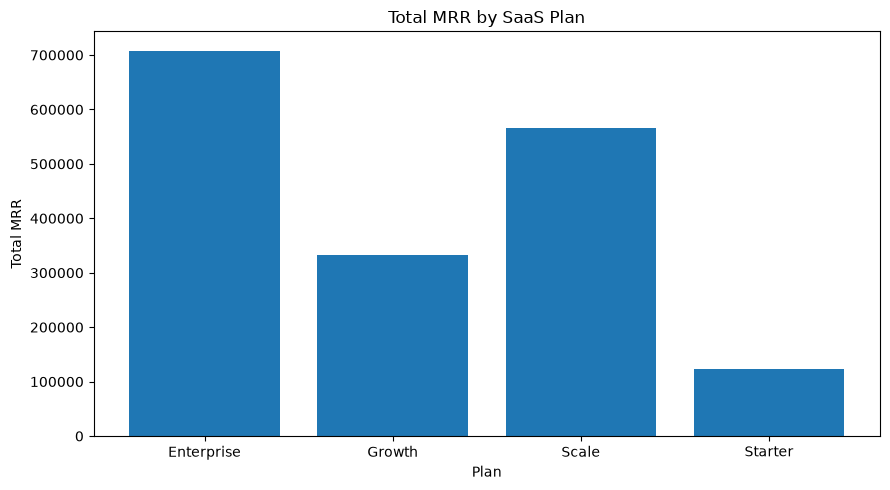

In [20]:
# MRR by plan

plt.figure(figsize=(9, 5))

plt.bar(
    plan_summary["plan_name"],
    plan_summary["total_mrr"]
)

plt.title("Total MRR by SaaS Plan")
plt.xlabel("Plan")
plt.ylabel("Total MRR")

plt.tight_layout()
plt.show()

In [21]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("data")

files = [
    "accounts.csv",
    "subscriptions.csv",
    "plans.csv",
    "invoices.csv",
    "payments.csv",
]

for filename in files:
    path = DATA_DIR / filename

    if not path.exists():
        print(f"\nMissing: {path.resolve()}")
        continue

    df = pd.read_csv(path)

    print(f"\n{'=' * 60}")
    print(f"FILE: {filename}")
    print(f"SHAPE: {df.shape}")
    print("\nCOLUMNS AND TYPES:")
    print(df.dtypes.to_string())
    print("\nSAMPLE:")
    print(df.head(3).to_string())


FILE: accounts.csv
SHAPE: (5000, 5)

COLUMNS AND TYPES:
account_id             str
created_at             str
region                 str
segment                str
acquisition_channel    str

SAMPLE:
  account_id  created_at region segment acquisition_channel
0    A000001  2024-05-24  LATAM     SMB             organic
1    A000002  2025-03-18   APAC     SMB             organic
2    A000003  2024-07-03   APAC     SMB         paid_search

FILE: subscriptions.csv
SHAPE: (5000, 8)

COLUMNS AND TYPES:
subscription_id        str
account_id             str
plan_id                str
started_at             str
ended_at               str
status                 str
seats                int64
mrr                float64

SAMPLE:
  subscription_id account_id      plan_id  started_at ended_at  status  seats    mrr
0         S000001    A000001   PLN_GROWTH  2024-06-11      NaN  active     13 199.00
1         S000002    A000002  PLN_STARTER  2025-04-07      NaN  active      3  49.00
2         S000003

In [22]:

from pathlib import Path
import pandas as pd
import numpy as np

# --------------------------------------------------
# 1. LOAD DATA
# --------------------------------------------------

DATA_DIR = Path("data")

accounts = pd.read_csv(DATA_DIR / "accounts.csv")
subscriptions = pd.read_csv(DATA_DIR / "subscriptions.csv")
plans = pd.read_csv(DATA_DIR / "plans.csv")
invoices = pd.read_csv(DATA_DIR / "invoices.csv")
payments = pd.read_csv(DATA_DIR / "payments.csv")

# Parse dates
for df, columns in [
    (accounts, ["created_at"]),
    (subscriptions, ["started_at", "ended_at"]),
    (invoices, ["invoice_date", "due_date"]),
    (payments, ["attempted_at"]),
]:
    for column in columns:
        df[column] = pd.to_datetime(df[column], errors="coerce")

print("Loaded all five datasets successfully.")


# --------------------------------------------------
# 2. DATA QUALITY AND DATE COVERAGE
# --------------------------------------------------

print("\n=== DATA QUALITY ===")

for name, df in {
    "accounts": accounts,
    "subscriptions": subscriptions,
    "plans": plans,
    "invoices": invoices,
    "payments": payments,
}.items():
    print(f"\n{name}")
    print("Rows:", len(df))
    print("Duplicate rows:", df.duplicated().sum())
    print("Missing cells:", int(df.isna().sum().sum()))

print("\n=== DATE COVERAGE ===")

for name, df, column in [
    ("Accounts", accounts, "created_at"),
    ("Subscriptions", subscriptions, "started_at"),
    ("Invoices", invoices, "invoice_date"),
    ("Payments", payments, "attempted_at"),
]:
    print(
        f"{name}:",
        df[column].min(),
        "to",
        df[column].max()
    )


# --------------------------------------------------
# 3. CUSTOMER AND SUBSCRIPTION METRICS
# --------------------------------------------------

print("\n=== SUBSCRIPTION STATUS ===")
print(subscriptions["status"].value_counts(dropna=False))

print("\n=== CURRENT SUBSCRIPTION MRR ===")
print(
    subscriptions.groupby("status")["mrr"]
    .agg(["count", "sum", "mean", "median"])
    .round(2)
)

print("\n=== ACCOUNTS BY SEGMENT ===")
print(accounts["segment"].value_counts(dropna=False))

print("\n=== ACCOUNTS BY REGION ===")
print(accounts["region"].value_counts(dropna=False))

print("\n=== ACQUISITION CHANNELS ===")
print(accounts["acquisition_channel"].value_counts(dropna=False))


# --------------------------------------------------
# 4. COMBINE ACCOUNT, SUBSCRIPTION AND PLAN DATA
# --------------------------------------------------

customer_data = (
    subscriptions
    .merge(
        accounts,
        on="account_id",
        how="left",
        validate="many_to_one"
    )
    .merge(
        plans,
        on="plan_id",
        how="left",
        validate="many_to_one"
    )
)

print("\n=== MRR BY PLAN ===")
print(
    customer_data.groupby("plan_name", dropna=False)
    .agg(
        subscriptions=("subscription_id", "nunique"),
        mrr=("mrr", "sum"),
        average_mrr=("mrr", "mean"),
        average_seats=("seats", "mean"),
        cancelled_subscriptions=(
            "status",
            lambda s: (s == "cancelled").sum()
        )
    )
    .round(2)
)

print("\n=== MRR BY CUSTOMER SEGMENT ===")
print(
    customer_data.groupby("segment", dropna=False)
    .agg(
        subscriptions=("subscription_id", "nunique"),
        mrr=("mrr", "sum"),
        average_mrr=("mrr", "mean"),
        cancelled_subscriptions=(
            "status",
            lambda s: (s == "cancelled").sum()
        )
    )
    .round(2)
)

print("\n=== MRR BY ACQUISITION CHANNEL ===")
print(
    customer_data.groupby("acquisition_channel", dropna=False)
    .agg(
        subscriptions=("subscription_id", "nunique"),
        mrr=("mrr", "sum"),
        average_mrr=("mrr", "mean"),
        cancelled_subscriptions=(
            "status",
            lambda s: (s == "cancelled").sum()
        )
    )
    .round(2)
)


# --------------------------------------------------
# 5. MONTHLY SUBSCRIPTION COHORTS AND CHURN
# --------------------------------------------------

valid_dates = subscriptions.dropna(subset=["started_at"])

if not valid_dates.empty:
    first_month = valid_dates["started_at"].min().to_period("M")
    last_month = max(
        subscriptions["started_at"].max(),
        subscriptions["ended_at"].max()
    )

    if pd.notna(last_month):
        last_month = last_month.to_period("M")

        monthly_rows = []

        for period in pd.period_range(first_month, last_month, freq="M"):
            month_start = period.start_time
            next_month = (period + 1).start_time

            # Subscriptions already started before this month
            # and not ended before its beginning.
            active_at_start = (
                (subscriptions["started_at"] < month_start)
                & (
                    subscriptions["ended_at"].isna()
                    | (subscriptions["ended_at"] >= month_start)
                )
            )

            # Subscriptions that ended during this month
            ended_during_month = (
                (subscriptions["ended_at"] >= month_start)
                & (subscriptions["ended_at"] < next_month)
            )

            start_count = int(active_at_start.sum())
            churned_count = int(ended_during_month.sum())

            monthly_rows.append({
                "month": str(period),
                "active_at_start": start_count,
                "ended_during_month": churned_count,
                "monthly_subscription_churn": (
                    churned_count / start_count
                    if start_count > 0 else np.nan
                ),
                "new_subscriptions": int(
                    (
                        (subscriptions["started_at"] >= month_start)
                        & (subscriptions["started_at"] < next_month)
                    ).sum()
                )
            })

        monthly_churn = pd.DataFrame(monthly_rows)

        print("\n=== MONTHLY SUBSCRIPTION COHORT METRICS ===")
        print(monthly_churn.tail(24).to_string(index=False))

        print(
            "\nNote: This is based on recorded subscription start/end "
            "dates. Validate dataset completeness and status consistency "
            "before using it to calibrate the simulation."
        )


# --------------------------------------------------
# 6. INVOICE AND PAYMENT METRICS
# --------------------------------------------------

print("\n=== INVOICE STATUS ===")
print(invoices["invoice_status"].value_counts(dropna=False))

print("\n=== INVOICE AMOUNTS BY STATUS ===")
print(
    invoices.groupby("invoice_status", dropna=False)["amount_due"]
    .agg(["count", "sum", "mean"])
    .round(2)
)

print("\n=== PAYMENT ATTEMPT STATUS ===")
print(payments["payment_status"].value_counts(dropna=False))

print("\n=== PAYMENT ATTEMPTS BY STATUS ===")
print(
    payments.groupby("payment_status", dropna=False)["amount"]
    .agg(["count", "sum", "mean"])
    .round(2)
)

# Join payments to invoices to examine payment outcomes
payment_invoice_data = payments.merge(
    invoices[["invoice_id", "invoice_status", "amount_due"]],
    on="invoice_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

print("\n=== PAYMENT-INVOICE LINKAGE ===")
print(payment_invoice_data["_merge"].value_counts())

print("\n=== PAYMENT ATTEMPTS BY INVOICE STATUS ===")
print(
    payment_invoice_data.groupby(
        ["invoice_status", "payment_status"],
        dropna=False
    ).size().unstack(fill_value=0)
)

print("\nAnalysis cell completed.")


Loaded all five datasets successfully.

=== DATA QUALITY ===

accounts
Rows: 5000
Duplicate rows: 0
Missing cells: 1247

subscriptions
Rows: 5000
Duplicate rows: 0
Missing cells: 4035

plans
Rows: 4
Duplicate rows: 0
Missing cells: 0

invoices
Rows: 85448
Duplicate rows: 0
Missing cells: 0

payments
Rows: 87287
Duplicate rows: 0
Missing cells: 0

=== DATE COVERAGE ===
Accounts: 2023-01-01 00:00:00 to 2025-09-30 00:00:00
Subscriptions: 2023-01-04 00:00:00 to 2025-10-29 00:00:00
Invoices: 2023-01-04 00:00:00 to 2025-12-28 00:00:00
Payments: 2023-01-06 00:00:00 to 2025-12-29 00:00:00

=== SUBSCRIPTION STATUS ===
status
active       4035
cancelled     965
Name: count, dtype: int64

=== CURRENT SUBSCRIPTION MRR ===
           count          sum   mean  median
status                                      
active      4035 1,387,441.00 343.85  199.00
cancelled    965   342,673.00 355.10  199.00

=== ACCOUNTS BY SEGMENT ===
segment
SMB           3522
mid_market    1173
enterprise     305
Name: 

In [23]:

import pandas as pd
from pathlib import Path

data_dir = Path("data")

accounts = pd.read_csv(data_dir / "accounts.csv")
subscriptions = pd.read_csv(data_dir / "subscriptions.csv")
plans = pd.read_csv(data_dir / "plans.csv")
invoices = pd.read_csv(data_dir / "invoices.csv")
payments = pd.read_csv(data_dir / "payments.csv")

# Parse relevant dates
for col in ["created_at"]:
    accounts[col] = pd.to_datetime(accounts[col], errors="coerce")

for col in ["started_at", "ended_at"]:
    subscriptions[col] = pd.to_datetime(
        subscriptions[col], errors="coerce"
    )

invoices["invoice_date"] = pd.to_datetime(
    invoices["invoice_date"], errors="coerce"
)
invoices["due_date"] = pd.to_datetime(
    invoices["due_date"], errors="coerce"
)
payments["attempted_at"] = pd.to_datetime(
    payments["attempted_at"], errors="coerce"
)

# 1. Do recorded subscription dates agree with status?
print("=== STATUS / DATE CONSISTENCY ===")
print(pd.crosstab(
    subscriptions["status"],
    subscriptions["ended_at"].notna(),
    rownames=["status"],
    colnames=["has_ended_at"]
))

print("\nCancelled subscriptions without an end date:",
      ((subscriptions["status"] == "cancelled") &
       subscriptions["ended_at"].isna()).sum())

print("Active subscriptions with an end date:",
      ((subscriptions["status"] == "active") &
       subscriptions["ended_at"].notna()).sum())

print("End date before start date:",
      (subscriptions["ended_at"] < subscriptions["started_at"]).sum())

print("\n=== SUBSCRIPTION STARTS BY MONTH ===")
print(
    subscriptions.assign(
        month=subscriptions["started_at"].dt.to_period("M")
    ).groupby("month").size().tail(18)
)

print("\n=== SUBSCRIPTION ENDINGS BY MONTH ===")
print(
    subscriptions.dropna(subset=["ended_at"])
    .assign(month=lambda x: x["ended_at"].dt.to_period("M"))
    .groupby("month").size().tail(18)
)

# 2. Reconstruct subscription activity at the end of each month.
# This uses recorded dates, independently of the status field.
month_ends = pd.date_range(
    subscriptions["started_at"].min().to_period("M").to_timestamp(),
    subscriptions[["started_at", "ended_at"]]
        .stack().max().to_period("M").to_timestamp("M"),
    freq="ME"
)

monthly_rows = []
for month_end in month_ends:
    started_by_end = subscriptions["started_at"].le(month_end)
    not_ended_by_end = (
        subscriptions["ended_at"].isna() |
        subscriptions["ended_at"].gt(month_end)
    )
    active_by_dates = started_by_end & not_ended_by_end

    monthly_rows.append({
        "month_end": month_end.date(),
        "active_by_dates": int(active_by_dates.sum()),
        "active_by_status": int(
            (subscriptions["status"] == "active").sum()
        )
    })

print("\n=== DATE-BASED ACTIVE SUBSCRIPTIONS ===")
print(pd.DataFrame(monthly_rows).tail(12).to_string(index=False))

# 3. Payment recovery at the invoice level.
payments_by_invoice = payments.groupby("invoice_id").agg(
    attempts=("payment_id", "count"),
    succeeded=("payment_status", lambda s: (s == "succeeded").sum()),
    failed=("payment_status", lambda s: (s == "failed").sum()),
    successful_amount=("amount", lambda s: 0.0)  # replaced below
)

successful_amounts = (
    payments[payments["payment_status"] == "succeeded"]
    .groupby("invoice_id")["amount"].sum()
)

payments_by_invoice["successful_amount"] = (
    successful_amounts.reindex(payments_by_invoice.index).fillna(0)
)

invoice_audit = invoices.merge(
    payments_by_invoice,
    left_on="invoice_id",
    right_index=True,
    how="left"
)

invoice_audit[["attempts", "succeeded", "failed"]] = (
    invoice_audit[["attempts", "succeeded", "failed"]].fillna(0)
)

print("\n=== INVOICE-LEVEL PAYMENT RECOVERY ===")
print("Invoices with at least one failed attempt:",
      int((invoice_audit["failed"] > 0).sum()))

print("Invoices with both failed and successful attempts:",
      int(((invoice_audit["failed"] > 0) &
           (invoice_audit["succeeded"] > 0)).sum()))

print("Invoices with failures but no successful attempt:",
      int(((invoice_audit["failed"] > 0) &
           (invoice_audit["succeeded"] == 0)).sum()))

print("\nInvoice status by payment outcome:")
invoice_audit["payment_outcome"] = "no recorded payment"
invoice_audit.loc[
    invoice_audit["succeeded"] > 0, "payment_outcome"
] = "has successful payment"
invoice_audit.loc[
    (invoice_audit["failed"] > 0) &
    (invoice_audit["succeeded"] == 0), "payment_outcome"
] = "failed attempts only"

print(pd.crosstab(
    invoice_audit["invoice_status"],
    invoice_audit["payment_outcome"]
))

print("\n=== OPEN INVOICE AGING ===")
as_of = invoices["invoice_date"].max()
open_invoices = invoices[invoices["invoice_status"] == "open"].copy()
open_invoices["days_past_due"] = (
    as_of - open_invoices["due_date"]
).dt.days

print("Reference date (latest invoice date):", as_of.date())
print("Open invoice amount:", round(open_invoices["amount_due"].sum(), 2))
print("Open invoices past due:", int(
    (open_invoices["days_past_due"] > 0).sum()
))
print("Open invoice aging (days):")
print(open_invoices["days_past_due"].describe().round(1))


=== STATUS / DATE CONSISTENCY ===
has_ended_at  False  True 
status                    
active         4035      0
cancelled         0    965

Cancelled subscriptions without an end date: 0
Active subscriptions with an end date: 0
End date before start date: 0

=== SUBSCRIPTION STARTS BY MONTH ===
month
2024-05    145
2024-06    138
2024-07    146
2024-08    172
2024-09    162
2024-10    143
2024-11    143
2024-12    174
2025-01    148
2025-02    141
2025-03    148
2025-04    147
2025-05    158
2025-06    148
2025-07    160
2025-08    150
2025-09    171
2025-10     72
Freq: M, dtype: int64

=== SUBSCRIPTION ENDINGS BY MONTH ===
month
2024-07    29
2024-08    49
2024-09    34
2024-10    41
2024-11    42
2024-12    41
2025-01    43
2025-02    41
2025-03    43
2025-04    47
2025-05    47
2025-06    40
2025-07    40
2025-08    36
2025-09    34
2025-10    44
2025-11    52
2025-12    44
Freq: M, dtype: int64

=== DATE-BASED ACTIVE SUBSCRIPTIONS ===
 month_end  active_by_dates  active_by_stat

In [24]:

# === FOUNDERVERSE: MONTHLY BASELINE METRICS ===

import pandas as pd

subs = subscriptions.copy()
subs["started_at"] = pd.to_datetime(subs["started_at"], errors="coerce")
subs["ended_at"] = pd.to_datetime(subs["ended_at"], errors="coerce")

first_month = subs["started_at"].min().to_period("M")
last_month = max(
    subs["started_at"].max(),
    subs["ended_at"].max()
).to_period("M")

rows = []

for period in pd.period_range(first_month, last_month, freq="M"):
    month_start = period.start_time
    month_end = period.end_time.normalize()

    started_this_month = subs["started_at"].between(
        month_start, month_end
    )

    ended_this_month = subs["ended_at"].between(
        month_start, month_end
    )

    # Customers active at the beginning of the month.
    active_at_start = (
        subs["started_at"].lt(month_start)
        & (
            subs["ended_at"].isna()
            | subs["ended_at"].ge(month_start)
        )
    )

    # Churn among customers already active at the start.
    established_churn = (
        active_at_start & ended_this_month
    )

    active_at_end = (
        subs["started_at"].le(month_end)
        & (
            subs["ended_at"].isna()
            | subs["ended_at"].gt(month_end)
        )
    )

    rows.append({
        "month": str(period),
        "active_at_start": int(active_at_start.sum()),
        "new_subscriptions": int(started_this_month.sum()),
        "established_cancellations": int(established_churn.sum()),
        "same_month_cancellations": int(
            (started_this_month & ended_this_month).sum()
        ),
        "churn_rate": (
            established_churn.sum() / active_at_start.sum()
            if active_at_start.sum() else None
        ),
        "active_at_end": int(active_at_end.sum()),
    })

monthly_baseline = pd.DataFrame(rows)

print("=== MONTHLY SUBSCRIPTION BASELINE ===")
print(monthly_baseline.tail(18).to_string(
    index=False,
    formatters={"churn_rate": lambda x: f"{x:.2%}" if pd.notna(x) else "N/A"}
))

# Summary excluding the potentially incomplete final month(s).
# This is a provisional cutoff, not proof that earlier months are complete.
calibration = monthly_baseline[
    (monthly_baseline["month"] >= "2024-01")
    & (monthly_baseline["month"] <= "2025-09")
]

print("\n=== PROVISIONAL CALIBRATION SUMMARY (JAN 2024–SEP 2025) ===")
print("Months:", len(calibration))
print("Average new subscriptions:",
      round(calibration["new_subscriptions"].mean(), 1))
print("Median new subscriptions:",
      round(calibration["new_subscriptions"].median(), 1))
print("Average monthly established-customer churn:",
      f"{calibration['churn_rate'].mean():.2%}")
print("Median monthly established-customer churn:",
      f"{calibration['churn_rate'].median():.2%}")
print("Total new subscriptions:", int(calibration["new_subscriptions"].sum()))
print("Total established cancellations:",
      int(calibration["established_cancellations"].sum()))

# Segment-level cancellation proportions: descriptive only.
print("\n=== CANCELLATION PROPORTION BY SEGMENT ===")
segment_check = subs.merge(
    accounts[["account_id", "segment"]],
    on="account_id",
    how="left"
)
print(
    segment_check.groupby("segment", dropna=False)
    .agg(
        subscriptions=("subscription_id", "count"),
        cancelled=("status", lambda s: (s == "cancelled").sum()),
        active=("status", lambda s: (s == "active").sum()),
    )
    .assign(
        cancellation_proportion=lambda d: d["cancelled"] / d["subscriptions"]
    )
    .round(3)
    .to_string()
)


=== MONTHLY SUBSCRIPTION BASELINE ===
  month  active_at_start  new_subscriptions  established_cancellations  same_month_cancellations churn_rate  active_at_end
2024-07             2399                146                         29                         0      1.21%           2516
2024-08             2516                172                         49                         0      1.95%           2639
2024-09             2639                162                         34                         0      1.29%           2767
2024-10             2767                143                         41                         0      1.48%           2869
2024-11             2869                143                         42                         0      1.46%           2970
2024-12             2970                174                         41                         0      1.38%           3103
2025-01             3103                148                         43                         0     

In [25]:

# ============================================================
# FOUNDERVERSE | FINAL DATA ANALYSIS + CALIBRATION EXPORT
# Run in notebooks/01_dataset_exploration.ipynb
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

DATA_DIR = Path("data")
OUTPUT_DIR = DATA_DIR / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Reload source datasets to make this cell independently runnable.
accounts = pd.read_csv(DATA_DIR / "accounts.csv")
subscriptions = pd.read_csv(DATA_DIR / "subscriptions.csv")
plans = pd.read_csv(DATA_DIR / "plans.csv")
invoices = pd.read_csv(DATA_DIR / "invoices.csv")
payments = pd.read_csv(DATA_DIR / "payments.csv")

# Parse dates.
accounts["created_at"] = pd.to_datetime(
    accounts["created_at"], errors="coerce"
)
subscriptions["started_at"] = pd.to_datetime(
    subscriptions["started_at"], errors="coerce"
)
subscriptions["ended_at"] = pd.to_datetime(
    subscriptions["ended_at"], errors="coerce"
)
invoices["invoice_date"] = pd.to_datetime(
    invoices["invoice_date"], errors="coerce"
)
invoices["due_date"] = pd.to_datetime(
    invoices["due_date"], errors="coerce"
)
payments["attempted_at"] = pd.to_datetime(
    payments["attempted_at"], errors="coerce"
)

# ------------------------------------------------------------
# 1. DATA QUALITY AUDIT
# ------------------------------------------------------------
quality_rows = []

for name, df in {
    "accounts": accounts,
    "subscriptions": subscriptions,
    "plans": plans,
    "invoices": invoices,
    "payments": payments,
}.items():
    quality_rows.append({
        "dataset": name,
        "rows": len(df),
        "columns": len(df.columns),
        "duplicate_rows": int(df.duplicated().sum()),
        "missing_cells": int(df.isna().sum().sum()),
    })

quality_df = pd.DataFrame(quality_rows)
quality_df.to_csv(OUTPUT_DIR / "data_quality_audit.csv", index=False)

# Check referential integrity.
fk_checks = {
    "subscription_accounts_missing": int(
        (~subscriptions["account_id"].isin(accounts["account_id"])).sum()
    ),
    "subscription_plans_missing": int(
        (~subscriptions["plan_id"].isin(plans["plan_id"])).sum()
    ),
    "invoice_subscriptions_missing": int(
        (~invoices["subscription_id"].isin(
            subscriptions["subscription_id"]
        )).sum()
    ),
    "payment_invoices_missing": int(
        (~payments["invoice_id"].isin(invoices["invoice_id"])).sum()
    ),
}

print("=== DATA QUALITY ===")
print(quality_df.to_string(index=False))
print("\n=== FOREIGN KEY CHECKS ===")
print(json.dumps(fk_checks, indent=2))

# ------------------------------------------------------------
# 2. MONTHLY SUBSCRIPTION METRICS
# ------------------------------------------------------------
# Definition:
# - New subscriptions: started during the calendar month.
# - Established cancellations: ended during the month and
#   were active at the start of that month.
# - Churn: established cancellations / active at start.
#
# Same-month starts and cancellations are reported separately.

first_period = subscriptions["started_at"].min().to_period("M")
last_period = max(
    subscriptions["started_at"].max(),
    subscriptions["ended_at"].max()
).to_period("M")

monthly_rows = []

for period in pd.period_range(first_period, last_period, freq="M"):
    month_start = period.start_time
    next_month_start = (period + 1).start_time

    started = subscriptions["started_at"]
    ended = subscriptions["ended_at"]

    starts_this_month = (
        started.ge(month_start) & started.lt(next_month_start)
    )
    ends_this_month = (
        ended.ge(month_start) & ended.lt(next_month_start)
    )

    active_at_start = (
        started.lt(month_start)
        & (ended.isna() | ended.ge(month_start))
    )

    established_cancellations = active_at_start & ends_this_month
    same_month_cancellations = starts_this_month & ends_this_month

    # Active immediately before the next month begins.
    active_at_end = (
        started.lt(next_month_start)
        & (ended.isna() | ended.ge(next_month_start))
    )

    start_count = int(active_at_start.sum())
    cancelled_count = int(established_cancellations.sum())

    monthly_rows.append({
        "month": str(period),
        "active_at_start": start_count,
        "new_subscriptions": int(starts_this_month.sum()),
        "established_cancellations": cancelled_count,
        "same_month_cancellations": int(
            same_month_cancellations.sum()
        ),
        "monthly_churn_rate": (
            cancelled_count / start_count if start_count else np.nan
        ),
        "active_at_end": int(active_at_end.sum()),
    })

monthly_df = pd.DataFrame(monthly_rows)

# Provisional calibration window: exclude the suspicious
# Oct-Dec 2025 tail, where recorded starts stop after October.
calibration_df = monthly_df[
    monthly_df["month"].between("2024-01", "2025-09")
].copy()

monthly_df.to_csv(
    OUTPUT_DIR / "monthly_subscription_metrics.csv", index=False
)
calibration_df.to_csv(
    OUTPUT_DIR / "calibration_window_monthly_metrics.csv", index=False
)

# ------------------------------------------------------------
# 3. JOIN BUSINESS DATA
# ------------------------------------------------------------
business_df = (
    subscriptions
    .merge(
        accounts[
            ["account_id", "segment", "region", "acquisition_channel"]
        ],
        on="account_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        plans,
        on="plan_id",
        how="left",
        validate="many_to_one",
    )
)

# Overall subscription metrics by plan.
plan_summary = business_df.groupby(
    "plan_name", dropna=False
).agg(
    subscriptions=("subscription_id", "nunique"),
    active_subscriptions=("status", lambda s: (s == "active").sum()),
    cancelled_subscriptions=(
        "status", lambda s: (s == "cancelled").sum()
    ),
    total_recorded_mrr=("mrr", "sum"),
    average_recorded_mrr=("mrr", "mean"),
    median_recorded_mrr=("mrr", "median"),
    average_seats=("seats", "mean"),
).reset_index()

plan_summary.to_csv(OUTPUT_DIR / "plan_summary.csv", index=False)

# Customer segment metrics.
segment_summary = business_df.groupby(
    "segment", dropna=False
).agg(
    subscriptions=("subscription_id", "nunique"),
    active_subscriptions=("status", lambda s: (s == "active").sum()),
    cancelled_subscriptions=(
        "status", lambda s: (s == "cancelled").sum()
    ),
    total_recorded_mrr=("mrr", "sum"),
    average_recorded_mrr=("mrr", "mean"),
).reset_index()

segment_summary["recorded_cancellation_proportion"] = (
    segment_summary["cancelled_subscriptions"]
    / segment_summary["subscriptions"]
)

segment_summary.to_csv(
    OUTPUT_DIR / "segment_summary.csv", index=False
)

# Acquisition channel metrics.
channel_summary = business_df.groupby(
    "acquisition_channel", dropna=False
).agg(
    subscriptions=("subscription_id", "nunique"),
    active_subscriptions=("status", lambda s: (s == "active").sum()),
    cancelled_subscriptions=(
        "status", lambda s: (s == "cancelled").sum()
    ),
    total_recorded_mrr=("mrr", "sum"),
    average_recorded_mrr=("mrr", "mean"),
).reset_index()

channel_summary["recorded_cancellation_proportion"] = (
    channel_summary["cancelled_subscriptions"]
    / channel_summary["subscriptions"]
)

channel_summary.to_csv(
    OUTPUT_DIR / "channel_summary.csv", index=False
)

# ------------------------------------------------------------
# 4. INVOICE AND PAYMENT ANALYSIS
# ------------------------------------------------------------
payments_per_invoice = payments.groupby("invoice_id").agg(
    payment_attempts=("payment_id", "count"),
    failed_attempts=(
        "payment_status", lambda s: (s == "failed").sum()
    ),
    successful_attempts=(
        "payment_status", lambda s: (s == "succeeded").sum()
    ),
).reset_index()

invoice_audit = invoices.merge(
    payments_per_invoice,
    on="invoice_id",
    how="left",
    validate="one_to_one",
)

for col in [
    "payment_attempts", "failed_attempts", "successful_attempts"
]:
    invoice_audit[col] = invoice_audit[col].fillna(0).astype(int)

invoice_audit["payment_outcome"] = np.select(
    [
        invoice_audit["successful_attempts"] > 0,
        invoice_audit["failed_attempts"] > 0,
    ],
    [
        "has_successful_payment",
        "failed_attempts_only",
    ],
    default="no_recorded_payment",
)

payment_recovery_summary = pd.crosstab(
    invoice_audit["invoice_status"],
    invoice_audit["payment_outcome"],
)

invoice_audit.to_csv(
    OUTPUT_DIR / "invoice_payment_audit.csv", index=False
)
payment_recovery_summary.to_csv(
    OUTPUT_DIR / "payment_recovery_summary.csv"
)

# ------------------------------------------------------------
# 5. CALIBRATION SUMMARY
# ------------------------------------------------------------
if calibration_df.empty:
    raise ValueError("Calibration window is empty. Check date coverage.")

active_subs = subscriptions[subscriptions["status"] == "active"]

# This is a provisional aggregate reference, not a universal
# customer-level revenue assumption.
active_mrr = float(active_subs["mrr"].sum())

calibration_summary = {
    "dataset_name": "FounderVerse subscription dataset",
    "calibration_window": {
        "start": str(calibration_df["month"].min()),
        "end": str(calibration_df["month"].max()),
        "months": int(len(calibration_df)),
    },
    "observed_subscription_metrics": {
        "mean_new_subscriptions_per_month": float(
            calibration_df["new_subscriptions"].mean()
        ),
        "median_new_subscriptions_per_month": float(
            calibration_df["new_subscriptions"].median()
        ),
        "mean_established_monthly_churn": float(
            calibration_df["monthly_churn_rate"].mean()
        ),
        "median_established_monthly_churn": float(
            calibration_df["monthly_churn_rate"].median()
        ),
        "total_new_subscriptions_in_window": int(
            calibration_df["new_subscriptions"].sum()
        ),
        "total_established_cancellations_in_window": int(
            calibration_df["established_cancellations"].sum()
        ),
    },
    "current_recorded_subscription_snapshot": {
        "active_subscriptions": int(
            (subscriptions["status"] == "active").sum()
        ),
        "cancelled_subscriptions": int(
            (subscriptions["status"] == "cancelled").sum()
        ),
        "active_subscription_mrr": active_mrr,
    },
    "payment_observations": {
        "invoice_count": int(len(invoices)),
        "payment_attempt_count": int(len(payments)),
        "invoices_with_failed_attempts": int(
            (invoice_audit["failed_attempts"] > 0).sum()
        ),
        "invoices_with_both_failed_and_successful_attempts": int(
            (
                (invoice_audit["failed_attempts"] > 0)
                & (invoice_audit["successful_attempts"] > 0)
            ).sum()
        ),
        "invoices_with_failed_attempts_only": int(
            (
                (invoice_audit["failed_attempts"] > 0)
                & (invoice_audit["successful_attempts"] == 0)
            ).sum()
        ),
    },
    "data_quality": {
        "missing_account_region_count": int(accounts["region"].isna().sum()),
        "subscription_status_date_consistency_passed": bool(
            (
                (
                    (subscriptions["status"] == "active")
                    & subscriptions["ended_at"].isna()
                )
                |
                (
                    (subscriptions["status"] == "cancelled")
                    & subscriptions["ended_at"].notna()
                )
            ).all()
        ),
        "foreign_key_checks": fk_checks,
    },
    "limitations": [
        "Observational data does not identify causal effects of founder decisions.",
        "Subscription acquisition records stop in October 2025 while cancellations continue through December 2025.",
        "Monthly metrics are provisional until historical data completeness is confirmed.",
        "Acquisition counts are not universal rates for startups of different sizes.",
        "Revenue, expenses, and cash-flow assumptions must be validated separately.",
        "Failed payment attempts must not be treated automatically as lost revenue.",
    ],
}

with open(
    OUTPUT_DIR / "calibration_summary.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(calibration_summary, f, indent=2, ensure_ascii=False)

# ------------------------------------------------------------
# 6. DISPLAY KEY OUTPUTS
# ------------------------------------------------------------
print("\n=== MONTHLY CALIBRATION METRICS ===")
print(calibration_df.to_string(
    index=False,
    formatters={
        "monthly_churn_rate": lambda x: (
            f"{x:.2%}" if pd.notna(x) else "N/A"
        )
    }
))

print("\n=== PLAN SUMMARY ===")
print(plan_summary.round(2).to_string(index=False))

print("\n=== SEGMENT SUMMARY ===")
print(segment_summary.round(3).to_string(index=False))

print("\n=== CHANNEL SUMMARY ===")
print(channel_summary.round(3).to_string(index=False))

print("\n=== PAYMENT RECOVERY ===")
print(payment_recovery_summary.to_string())

print("\n=== CALIBRATION SUMMARY ===")
print(json.dumps(calibration_summary, indent=2))

print(f"\nSaved analysis artifacts to: {OUTPUT_DIR.resolve()}")


=== DATA QUALITY ===
      dataset  rows  columns  duplicate_rows  missing_cells
     accounts  5000        5               0           1247
subscriptions  5000        8               0           4035
        plans     4        4               0              0
     invoices 85448        6               0              0
     payments 87287        5               0              0

=== FOREIGN KEY CHECKS ===
{
  "subscription_accounts_missing": 0,
  "subscription_plans_missing": 0,
  "invoice_subscriptions_missing": 0,
  "payment_invoices_missing": 0
}

=== MONTHLY CALIBRATION METRICS ===
  month  active_at_start  new_subscriptions  established_cancellations  same_month_cancellations monthly_churn_rate  active_at_end
2024-01             1667                141                         15                         0              0.90%           1793
2024-02             1793                140                         22                         0              1.23%           1911
2024-03       

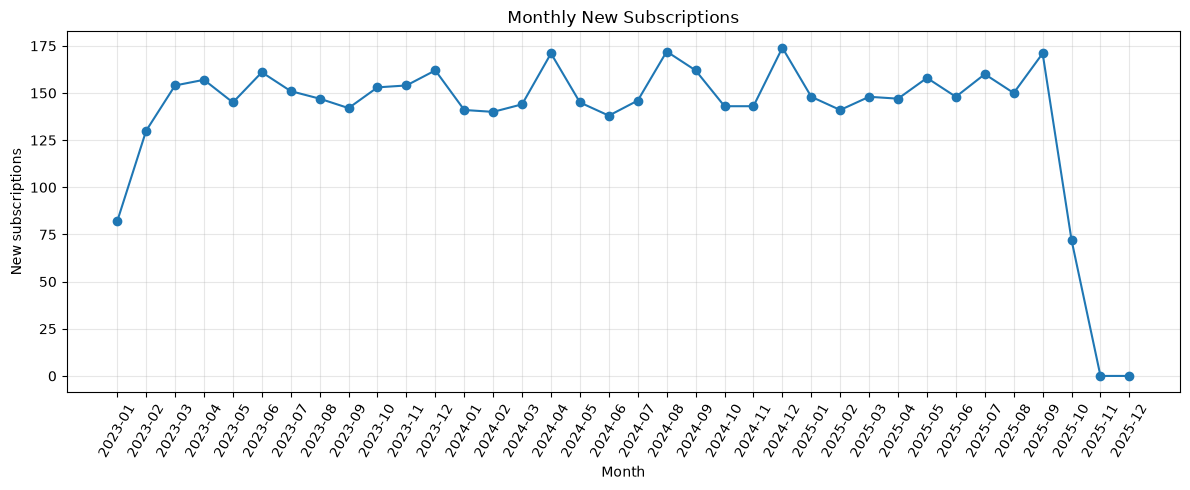

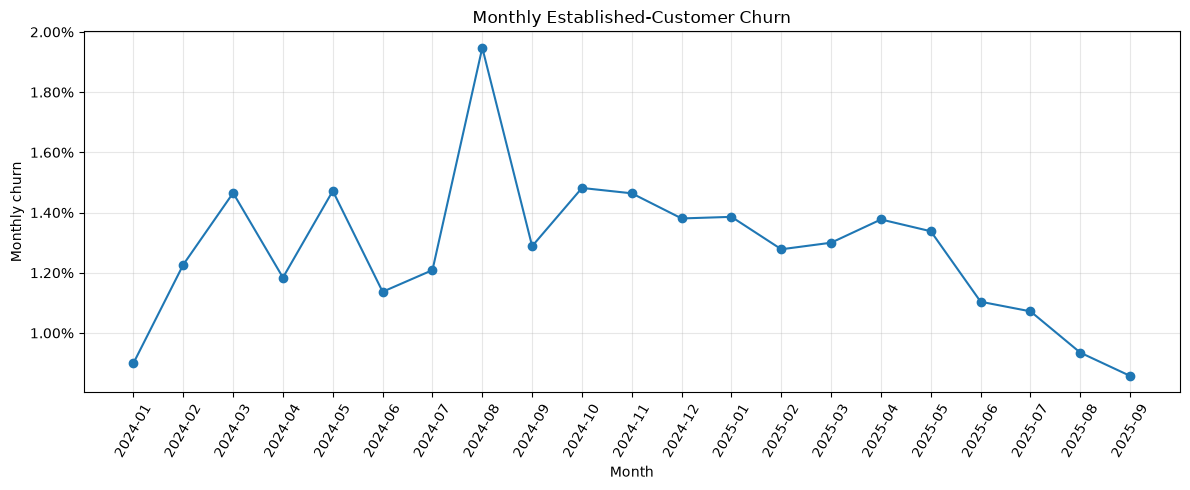

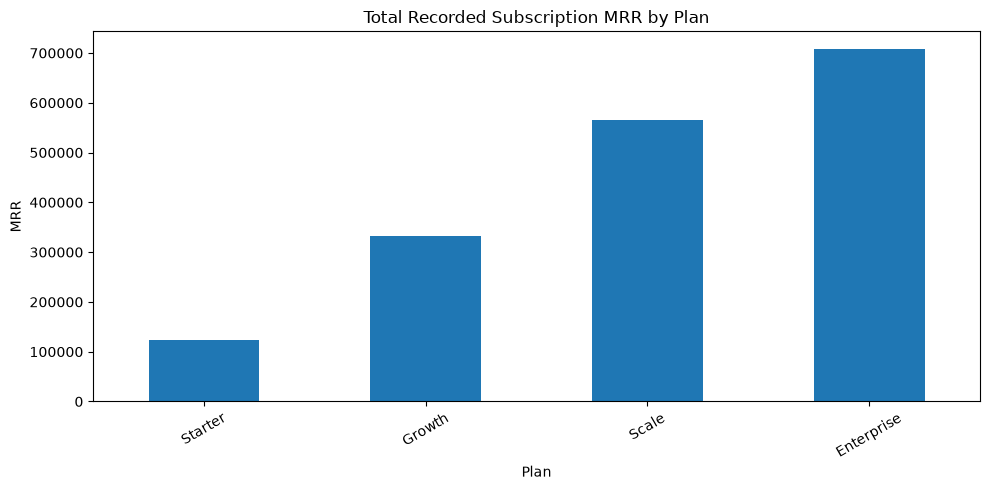

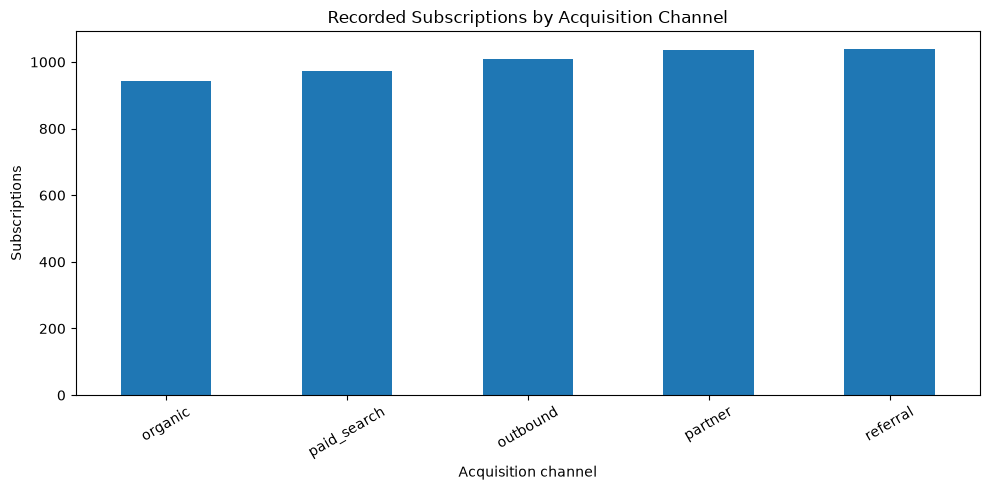

In [26]:

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# 1. New subscriptions over time
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
    monthly_df["month"],
    monthly_df["new_subscriptions"],
    marker="o",
)
ax.set_title("Monthly New Subscriptions")
ax.set_xlabel("Month")
ax.set_ylabel("New subscriptions")
ax.tick_params(axis="x", rotation=60)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

# 2. Monthly established-customer churn
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
    calibration_df["month"],
    calibration_df["monthly_churn_rate"],
    marker="o",
)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Monthly Established-Customer Churn")
ax.set_xlabel("Month")
ax.set_ylabel("Monthly churn")
ax.tick_params(axis="x", rotation=60)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

# 3. Revenue distribution by plan
fig, ax = plt.subplots(figsize=(10, 5))
plan_summary.sort_values("total_recorded_mrr").plot(
    kind="bar",
    x="plan_name",
    y="total_recorded_mrr",
    legend=False,
    ax=ax,
)
ax.set_title("Total Recorded Subscription MRR by Plan")
ax.set_xlabel("Plan")
ax.set_ylabel("MRR")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

# 4. Acquisition channel comparison
fig, ax = plt.subplots(figsize=(10, 5))
channel_summary.sort_values(
    "subscriptions"
).plot(
    kind="bar",
    x="acquisition_channel",
    y="subscriptions",
    legend=False,
    ax=ax,
)
ax.set_title("Recorded Subscriptions by Acquisition Channel")
ax.set_xlabel("Acquisition channel")
ax.set_ylabel("Subscriptions")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()


In [27]:

# Compare earlier vs later observations in the calibration window.
# This is a stability diagnostic, not a causal analysis.

stability_df = calibration_df.copy()
stability_df["period_group"] = np.where(
    stability_df["month"] <= "2024-12",
    "Earlier period (through Dec 2024)",
    "Later period (Jan-Sep 2025)",
)

stability_summary = stability_df.groupby(
    "period_group", sort=False
).agg(
    months=("month", "count"),
    mean_new_subscriptions=("new_subscriptions", "mean"),
    median_new_subscriptions=("new_subscriptions", "median"),
    mean_monthly_churn=("monthly_churn_rate", "mean"),
    median_monthly_churn=("monthly_churn_rate", "median"),
).reset_index()

print("=== ACQUISITION / CHURN STABILITY CHECK ===")
print(stability_summary.round(4).to_string(index=False))

if len(stability_summary) == 2:
    earlier = stability_summary.iloc[0]
    later = stability_summary.iloc[1]

    print("\nChange in average new subscriptions:",
          round(
              later["mean_new_subscriptions"]
              - earlier["mean_new_subscriptions"], 2
          ))

    print("Change in average monthly churn (percentage points):",
          round(
              100 * (
                  later["mean_monthly_churn"]
                  - earlier["mean_monthly_churn"]
              ), 3
          ))

print(
    "\nInterpretation: if acquisition or churn shifts materially, "
    "avoid treating one pooled average as a fixed law. Investigate "
    "the time pattern and use sensitivity analysis or a simpler "
    "documented baseline until a more reliable model is justified."
)


=== ACQUISITION / CHURN STABILITY CHECK ===
                     period_group  months  mean_new_subscriptions  median_new_subscriptions  mean_monthly_churn  median_monthly_churn
Earlier period (through Dec 2024)      12                  151.58                    144.50                0.01                  0.01
      Later period (Jan-Sep 2025)       9                  152.33                    148.00                0.01                  0.01

Change in average new subscriptions: 0.75
Change in average monthly churn (percentage points): -0.163

Interpretation: if acquisition or churn shifts materially, avoid treating one pooled average as a fixed law. Investigate the time pattern and use sensitivity analysis or a simpler documented baseline until a more reliable model is justified.
